**ESOPHAGEAL CANCER CLASSIFICATION USING MOBILENETV2 FOR SAVE IMAGES**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Import necessary libraries
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Define the paths to your dataset directories
train_dir = '/content/drive/MyDrive/Danat/EC/inceptionv3_later/SAVE_split/train'
val_dir = '/content/drive/MyDrive/Danat/EC/inceptionv3_later/SAVE_split/val'
test_dir = '/content/drive/MyDrive/Danat/EC/inceptionv3_later/SAVE_split/test'

# Set image size and batch size
IMG_SIZE = (640, 640)
BATCH_SIZE = 32

# Data augmentation for the training set
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Only rescale for validation and test sets
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

# Load the data
train_data = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_data = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_data = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)



Found 751 images belonging to 3 classes.
Found 214 images belonging to 3 classes.
Found 109 images belonging to 3 classes.


In [ ]:
# Load the MobileNetV2 model with pretrained weights
base_model = MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet')

# Freeze the base model layers
base_model.trainable = False

# Build the model
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dense(train_data.num_classes, activation='softmax')  # Adjust the output layer based on the number of classes
])

# Compile the model
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Set up callbacks
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_model_danat.keras', monitor='val_loss', save_best_only=True)



<ipython-input-3-33807a0badc0>:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet')


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Train the model
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=100,  # You can increase the number of epochs if necessary
    callbacks=[early_stopping, checkpoint]
)



Epoch 1/100


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


24/24 ━━━━━━━━━━━━━━━━━━━━ 289s 9s/step - accuracy: 0.5986 - loss: 0.8726 - val_accuracy: 0.8131 - val_loss: 0.4768
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 67s 2s/step - accuracy: 0.8033 - loss: 0.5067 - val_accuracy: 0.8271 - val_loss: 0.4747
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 66s 2s/step - accuracy: 0.8325 - loss: 0.4595 - val_accuracy: 0.8551 - val_loss: 0.3819
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 66s 2s/step - accuracy: 0.8456 - loss: 0.4135 - val_accuracy: 0.8692 - val_loss: 0.3824
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 66s 2s/step - accuracy: 0.8513 - loss: 0.3898 - val_accuracy: 0.8551 - val_loss: 0.4489
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 66s 2s/step - accuracy: 0.8382 - loss: 0.4071 - val_accuracy: 0.8551 - val_loss: 0.3876
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 66s 2s/step - accuracy: 0.8628 - loss: 0.3598 - val_accuracy: 0.8551 - val_loss: 0.4303
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 66s 2s/step - accuracy: 0.8865 - loss: 0.3031 - val_accuracy: 0.8645 - val_loss: 0.

In [ ]:
# Evaluate the model on the test set
test_loss, test_accuracy = model.evaluate(test_data)
print(f'Test Accuracy: {test_accuracy:.2f}')



4/4 ━━━━━━━━━━━━━━━━━━━━ 21s 7s/step - accuracy: 0.8559 - loss: 0.3721
Test Accuracy: 0.87


4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step
              precision    recall  f1-score   support

   Dysplasia       0.85      0.85      0.85        41
      Normal       0.94      0.85      0.89        34
         SCC       0.84      0.91      0.87        34

    accuracy                           0.87       109
   macro avg       0.88      0.87      0.87       109
weighted avg       0.87      0.87      0.87       109



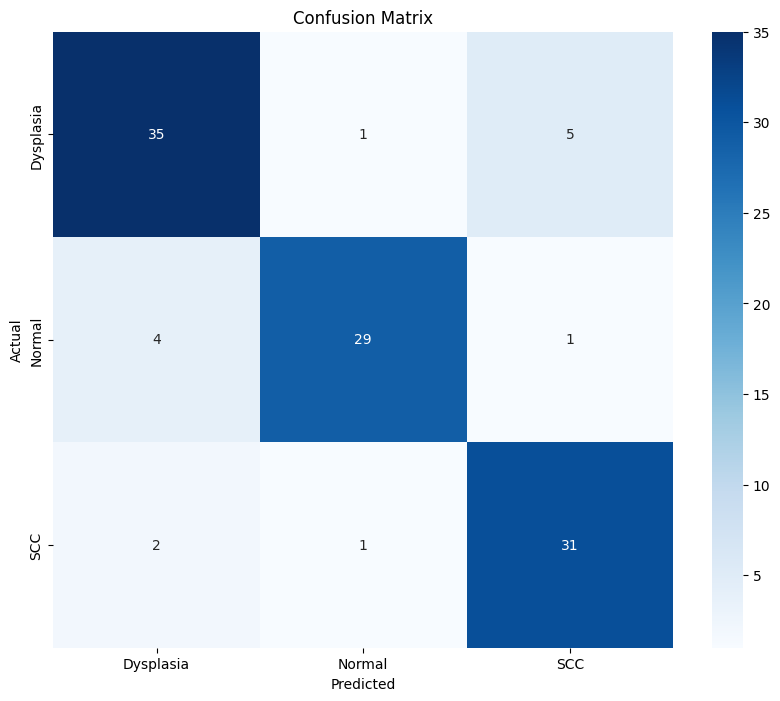

In [ ]:
# Load the best model
model.load_weights('best_model_danat.keras')

# Predict on the test set
predictions = model.predict(test_data)
predicted_classes = tf.argmax(predictions, axis=1)
true_classes = test_data.classes
class_labels = list(test_data.class_indices.keys())

# Print classification report
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(true_classes, predicted_classes, target_names=class_labels))

# Plot confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(true_classes, predicted_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


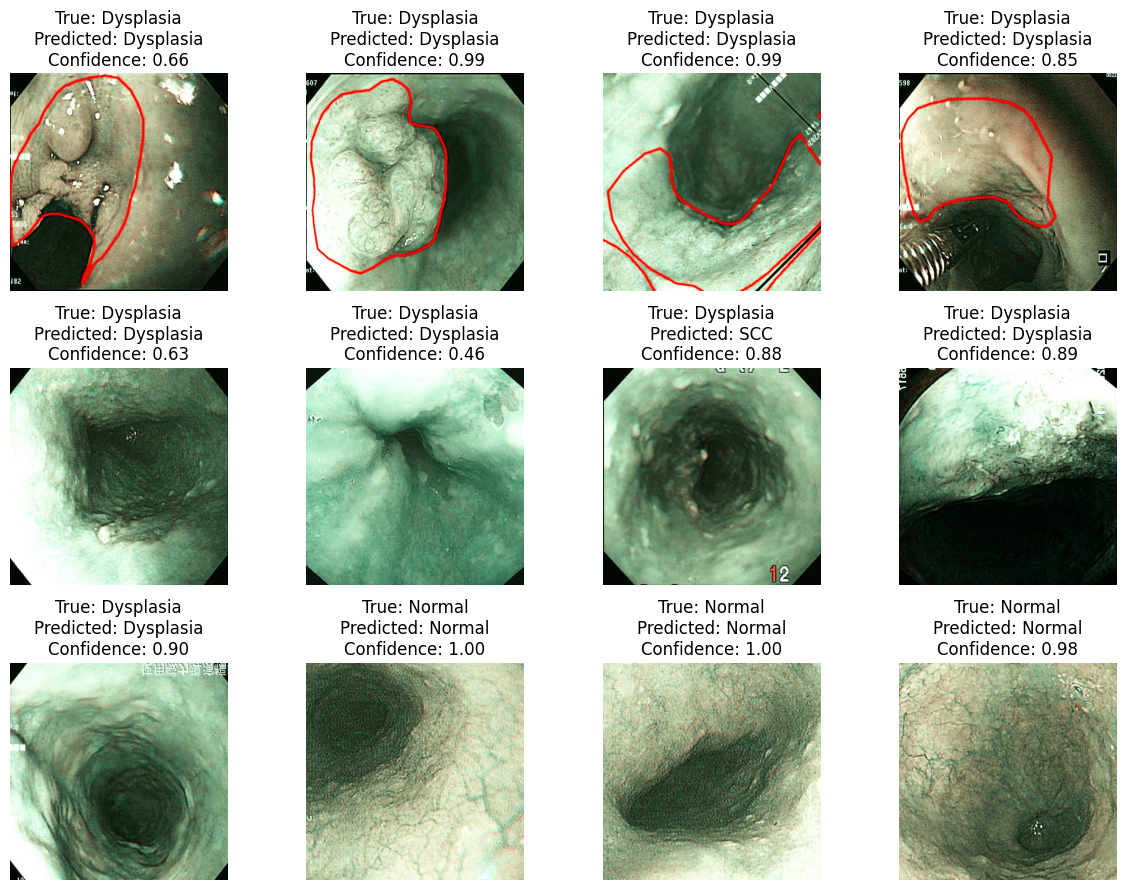

In [ ]:

test_images, true_labels = next(test_data)

# Select the first 12 images
test_images = test_images[:12]
true_labels = true_labels[:12]

# Predict on the selected images
predictions = model.predict(test_images)

# Get the predicted class for each image
predicted_classes = np.argmax(predictions, axis=1)

# Get the confidence score for each prediction
confidence_scores = np.max(predictions, axis=1)

# Get the true class labels
true_classes = np.argmax(true_labels, axis=1)

# Display the images with their true and predicted labels and confidence scores
plt.figure(figsize=(12, 9))  # Adjust figure size as needed
for i in range(12):
  plt.subplot(3, 4, i + 1)  # 3 rows, 4 columns
  plt.imshow(test_images[i])
  plt.title(f"True: {class_labels[true_classes[i]]}\nPredicted: {class_labels[predicted_classes[i]]}\nConfidence: {confidence_scores[i]:.2f}")
  plt.axis('off')  # Hide axis
plt.tight_layout()
plt.show()


In [ ]:
from google.colab import files

# Download the model file
files.download('best_model_danat.keras')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

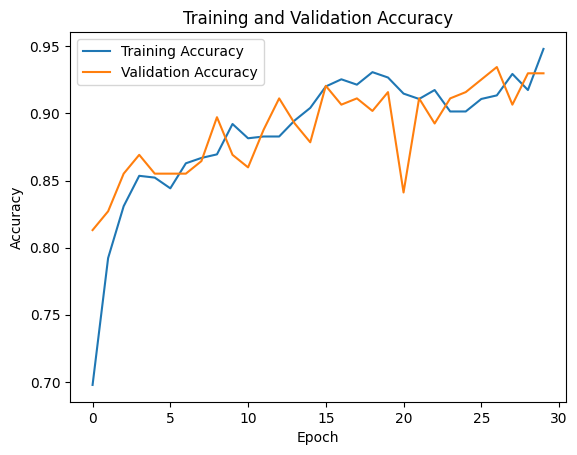

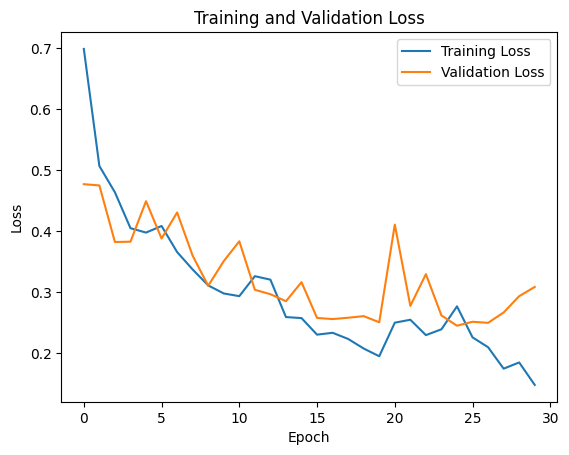

In [ ]:
# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()
